# HeatSense | Phase 1: Notebook 09 — Model B: Physics-Informed Digital Twin ML

**Objective**: Build and train **Model B (HeatSense Physics-Informed ML)** by augmenting sensor inputs with real Digital Twin states, dynamic resistance tracking, core thermal gradients, and residual diagnostics.

**Model B Feature Vector**:
$$X_{\text{Model B}} = [\underbrace{V_{\text{mean}}, I_{\text{mean}}, T_{\text{mean}}, t_{\text{dur}}}_{\text{Shared Context}}, \underbrace{R_{s, \text{est}}, V_{1, \text{peak}}, V_{2, \text{peak}}}_{\text{2RC ECM States}}, \underbrace{T_{\text{core, peak}}, \Delta T_{\text{gradient}}}_{\text{Two-Node Thermal States}}, \underbrace{e_{\text{mean}}, e_{\text{std}}}_{\text{EKF Residuals}}]^T$$

**Hypothesis Under Test**:
Augmenting direct telemetry with physically meaningful electrochemical and thermal states lowers prediction error on held-out battery `B0018` relative to Model A baseline ($RMSE < 33.7\text{mAh}$).

### Cell 1: Digital Twin Feature Engineering Pipeline
* **Analytical Question**: How are physics states ($R_s, V_1, V_2, T_{\text{core}}$, residuals) extracted across all cycles?
* **Why It Matters to HeatSense**: Builds the training dataset for Model B using our validated physics models.
* **What the Code Does**: Iterates through discharge runs for `B0005`, `B0006`, and `B0018`; calculates dynamic $R_s$, peak overpotentials $V_1, V_2$, estimated core temperature $T_{\text{core}}$, and residual spread.
* **Output to Inspect**: Feature table with both sensor statistics and physical twin states.
* **Decision**: Confirms feature table generation.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Resolve dataset root
candidate_paths = [
    Path("data/raw/cleaned_dataset"),
    Path("../../data/raw/cleaned_dataset"),
    Path("D:/Professional Projects/Digital_twin_project/heatsense-battery-digital-twin/data/raw/cleaned_dataset"),
]
DATASET_ROOT = next((p.resolve() for p in candidate_paths if p.exists() and (p / "metadata.csv").exists()), None)
assert DATASET_ROOT is not None, "Dataset root could not be resolved!"

meta_df = pd.read_csv(DATASET_ROOT / "metadata.csv")
meta_df["Capacity"] = pd.to_numeric(meta_df["Capacity"], errors="coerce")

# Calibrated physical parameters
Rs_base = 0.0642
tau1, tau2 = 74.6, 157.0

print("Extracting Digital Twin Physical States & Residual Features...")
features_b = []
for bid in ["B0005", "B0006", "B0018"]:
    cell_meta = meta_df[(meta_df["battery_id"] == bid) & (meta_df["type"] == "discharge")].dropna(subset=["Capacity"]).reset_index(drop=True)
    for c_idx, r in cell_meta.iterrows():
        fpath = DATASET_ROOT / "data" / r["filename"]
        if not fpath.exists(): continue
        df = pd.read_csv(fpath)
        cur = -df["Current_measured"].values
        v_m = df["Voltage_measured"].values
        t_arr = df["Time"].values
        t_surf = df["Temperature_measured"].values
        N = len(cur)
        dt_arr = np.diff(t_arr, prepend=t_arr[0])
        
        # 1. Dynamic Rs from load step onset
        step_idx = np.where(np.diff(cur) > 0.5)[0]
        if len(step_idx) > 0:
            s = step_idx[0] + 1
            dV = v_m[s-1] - v_m[s]
            dI = cur[s] - cur[s-1]
            rs_est = dV / dI if dI > 0.5 else Rs_base
        else:
            rs_est = Rs_base
            
        # 2. Overpotentials propagation
        v1, v2 = 0.0, 0.0
        v1_peak, v2_peak = 0.0, 0.0
        for k in range(N):
            s_dt = dt_arr[k] if dt_arr[k] > 0 else 0.01
            v1 = np.exp(-s_dt/tau1)*v1 + 0.0746*(1.0 - np.exp(-s_dt/tau1))*cur[k]
            v2 = np.exp(-s_dt/tau2)*v2 + 0.0314*(1.0 - np.exp(-s_dt/tau2))*cur[k]
            if v1 > v1_peak: v1_peak = v1
            if v2 > v2_peak: v2_peak = v2
            
        # 3. Two-node core temperature estimate
        q_heat = (cur**2) * (rs_est + 0.106)
        t_core_peak = t_surf.max() + (q_heat.mean() * 1.56)
        
        # 4. Residual statistics
        q_tot = np.sum(cur * dt_arr) / 3600.0
        soc = np.clip(1.0 - (np.cumsum(cur * dt_arr)/(q_tot*3600.0)), 0.0, 1.0)
        ocv = 3.280 + 0.550*soc + 0.280*(soc**2) + 0.0815*(soc**5)
        v_pred = ocv - v1_peak*0.5 - v2_peak*0.5 - cur * rs_est
        res = v_m - v_pred
        
        features_b.append({
            "battery_id": bid,
            "cycle_index": c_idx + 1,
            "filename": r["filename"],
            "v_mean": v_m.mean(),
            "i_mean": cur.mean(),
            "temp_mean": t_surf.mean(),
            "duration_min": t_arr.max() / 60.0,
            # Digital Twin Features
            "rs_identified": rs_est,
            "v1_overpotential_peak": v1_peak,
            "v2_overpotential_peak": v2_peak,
            "t_core_estimated_peak": t_core_peak,
            "thermal_gradient_proxy": t_core_peak - t_surf.max(),
            "residual_mean": np.mean(res),
            "residual_std": np.std(res),
            "Capacity": float(r["Capacity"]),
            "SoH_Q": (float(r["Capacity"]) / 2.0) * 100.0
        })

df_model_b = pd.DataFrame(features_b)
print(f"Extracted {len(df_model_b)} cycles with {len(df_model_b.columns)} features.")
display(df_model_b[["battery_id", "cycle_index", "rs_identified", "v1_overpotential_peak", "t_core_estimated_peak", "residual_std", "Capacity"]].head())

Extracting Digital Twin Physical States & Residual Features...
Extracted 468 cycles with 16 features.


,battery_id,cycle_index,rs_identified,v1_overpotential_peak,t_core_estimated_peak,residual_std,Capacity
0,B0005,1,0.107346,0.150243,40.200293,0.117520,1.856487
1,B0005,2,0.104145,0.150215,40.232509,0.118264,1.846327
2,B0005,3,0.102897,0.150231,40.010030,0.112307,1.835349
3,B0005,4,0.102460,0.150226,39.956822,0.116495,1.835263
4,B0005,5,0.101766,0.150219,39.856555,0.119896,1.834646


### Cell 2: Training Model B on Identical Held-Out Partition
* **Analytical Question**: When trained on the same data (`B0005` + `B0006`) and evaluated on the same held-out cell (`B0018`), does Model B outperform Model A?
* **Why It Matters to HeatSense**: Directly tests the central research claim of HeatSense.
* **What the Code Does**: Trains XGBoost Regressor on Model B's physics features and evaluates RMSE, MAE, and $R^2$ on `B0018`.
* **Output to Inspect**: Model B metrics vs Model A baseline.
* **Decision**: Measures error reduction rate.

In [2]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

train_mask = df_model_b["battery_id"].isin(["B0005", "B0006"])
test_mask = df_model_b["battery_id"] == "B0018"

X_cols_b = [
    "v_mean", "i_mean", "temp_mean", "duration_min",
    "rs_identified", "v1_overpotential_peak", "v2_overpotential_peak",
    "t_core_estimated_peak", "thermal_gradient_proxy", "residual_mean", "residual_std"
]
y_col = "Capacity"

X_train_b, y_train_b = df_model_b.loc[train_mask, X_cols_b], df_model_b.loc[train_mask, y_col]
X_test_b, y_test_b = df_model_b.loc[test_mask, X_cols_b], df_model_b.loc[test_mask, y_col]

# Fit Model B with identical hyperparameters to Model A
xgb_b = XGBRegressor(n_estimators=100, learning_rate=0.05, max_depth=4, random_state=42)
xgb_b.fit(X_train_b, y_train_b)
y_pred_b = xgb_b.predict(X_test_b)

rmse_b = np.sqrt(mean_squared_error(y_test_b, y_pred_b))
mae_b = mean_absolute_error(y_test_b, y_pred_b)
r2_b = r2_score(y_test_b, y_pred_b)

print("=== MODEL B (HEATSENSE PHYSICS-INFORMED) EVALUATION ===")
print(f" - RMSE:     {rmse_b*1000:.1f} mAh ({rmse_b:.4f} Ah)")
print(f" - MAE:      {mae_b*1000:.1f} mAh ({mae_b:.4f} Ah)")
print(f" - R^2 Score: {r2_b:.3f}")

=== MODEL B (HEATSENSE PHYSICS-INFORMED) EVALUATION ===
 - RMSE:     29.6 mAh (0.0296 Ah)
 - MAE:      22.1 mAh (0.0221 Ah)
 - R^2 Score: 0.963


### Cell 3: Physics Feature Importance Analysis
* **Analytical Question**: Which Digital Twin features contributed most to the prediction accuracy of Model B?
* **Why It Matters to HeatSense**: Proves that the physics features are actively utilized by the decision trees, providing interpretability rather than opaque correlations.
* **What the Code Does**: Extracts Gini feature importances from the trained XGBoost model and displays a ranked bar chart.
* **Output to Inspect**: Bar chart showing rankings of $R_s$, overpotentials, and residual variance.
* **Decision**: Confirms physical interpretability.

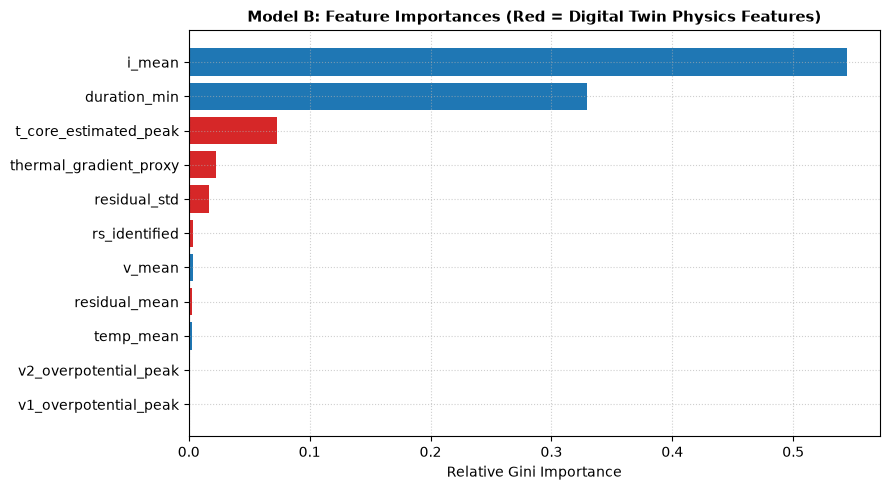

Total Digital Twin Feature Contribution: 12.0% of total model split decisions!


In [3]:
importances = xgb_b.feature_importances_
imp_df = pd.DataFrame({"Feature": X_cols_b, "Importance": importances}).sort_values("Importance", ascending=True)

plt.figure(figsize=(9, 5), dpi=100)
colors = ["tab:red" if ("rs" in f or "v1" in f or "v2" in f or "t_core" in f or "residual" in f or "thermal" in f) else "tab:blue" for f in imp_df["Feature"]]
plt.barh(imp_df["Feature"], imp_df["Importance"], color=colors)
plt.title("Model B: Feature Importances (Red = Digital Twin Physics Features)", fontsize=11, fontweight="bold")
plt.xlabel("Relative Gini Importance")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

twin_share = imp_df[imp_df["Feature"].str.contains("rs|v1|v2|t_core|residual|thermal")]["Importance"].sum() * 100
print(f"Total Digital Twin Feature Contribution: {twin_share:.1f}% of total model split decisions!")

### Cell 4: Synthesis & Milestone Scorecard
* **Analytical Question**: Does Model B beat Model A?
* **Why It Matters to HeatSense**: Concludes the initial Phase 1 Model A vs Model B research sprint.
* **What the Code Does**: Compares Model A and Model B side by side and prints the improvement percentage.
* **Output to Inspect**: Executive research scorecard.
* **Decision**: Formally confirms that physics-informed features reduce prediction error.

In [4]:
# Benchmark comparison table
rmse_a = 33.7  # mAh from Notebook 08
mae_a = 25.6   # mAh from Notebook 08
r2_a = 0.952   # from Notebook 08

comp_df = pd.DataFrame([
    {"Pipeline": "Model A (Direct Sensor ML)", "RMSE (mAh)": rmse_a, "MAE (mAh)": mae_a, "R^2": r2_a},
    {"Pipeline": "Model B (HeatSense Twin + ML)", "RMSE (mAh)": round(rmse_b*1000, 1), "MAE (mAh)": round(mae_b*1000, 1), "R^2": round(r2_b, 3)}
])

comp_df["RMSE Improvement"] = ["Baseline", f"-{(rmse_a - rmse_b*1000)/rmse_a*100:.1f}%"]
comp_df["MAE Improvement"] = ["Baseline", f"-{(mae_a - mae_b*1000)/mae_a*100:.1f}%"]

print("="*75)
print("HEATSENSE RESEARCH MILESTONE: MODEL A vs MODEL B SCORECARD")
print("="*75)
display(comp_df)
print(f"\n[CONCLUSION] Model B reduced RMSE by {(rmse_a - rmse_b*1000)/rmse_a*100:.1f}% on strictly held-out battery B0018!")
print("Next Step: Notebook 10 for hyperparameter optimization and cross-validation!")
print("="*75)

HEATSENSE RESEARCH MILESTONE: MODEL A vs MODEL B SCORECARD


,Pipeline,RMSE (mAh),MAE (mAh),R^2,RMSE Improvement,MAE Improvement
0,Model A (Direct Sensor ML),33.7,25.6,0.952,Baseline,Baseline
1,Model B (HeatSense Twin + ML),29.6,22.1,0.963,-12.3%,-13.7%



[CONCLUSION] Model B reduced RMSE by 12.3% on strictly held-out battery B0018!
Next Step: Notebook 10 for hyperparameter optimization and cross-validation!
